# Who gets the good Batman stories?

Doug Moench and Kelley Jones made both *Red Rain* and *Unseen*. BatChat ranks them **710 places apart**: #6 and #716. Same writer, same artist, very different results.

We'll start with writers, characters, and publication years. Then we'll look at artistic partnerships, coloring, lettering, and what plot summaries miss.

The data contains **740 stories ranked by BatChat**, the Batman podcast hosted by Matt Lazorwitz and Will Nevin. Each row is one story. **Rank 1 is best.** We use the **2026-10-21** snapshot of [ComicsXF's list](https://comicsxf.com/batchat-rankings/).

<details><summary>Reading the figures</summary>

Lower ranks are better. A median is the middle rank in a group. Most figures also show individual stories or the middle half of the ranks, so you can see how much the books vary. The [metric key](../references/data_dictionary.md#analysis-metrics-and-sign-conventions) defines the exported columns.

</details>

*Part of [BatRank](https://github.com/ddofer/BatRank), by [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ).*

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path('/kaggle/input').glob('**/data/processed/stories.csv')]
DATA_ROOT = next(p for p in candidates if (p/'data/processed/stories.csv').exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import (load_data, split_set, grouped_folds, feature_frame, regression,
    fit_oof, model_summary, bootstrap_gain, block_importance, creator_table, save_figure,
    COLORS, ROLES, BIBLIOGRAPHY, CRAFT, CAST, AWARDS, AWARD_CONTROLS)
ROOT, REPORT, s, issues = load_data()
N = len(s)
s['preference'] = 1-s.rank_percentile
print(f'{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}')

creators=pd.read_csv(ROOT/'data/processed/creators.csv')
credits=pd.read_csv(ROOT/'data/processed/story_creators.csv')
creator_awards=pd.read_csv(ROOT/'data/processed/creator_awards.csv')


740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## A quick tour of the reading list

Chuck Dixon leads the writer count with **34 stories**, followed by Alan Grant with **31** and Dennis O'Neil with **28**. These are counts from the podcast's list, not everything the writers published.

The decade comparison is less predictable. The 2020s have a median rank of **300**, close to the 1980s' **310**. Each bar spans the middle half of a decade's ranks. The broad spreads leave no decade a safe bet. **Farther left is better.** Treat the oldest decades cautiously; only three stories represent the 1930s.

<details><summary>Which writers and years are counted?</summary>

The writer panel includes 677 stories whose writers could be identified completely. A co-written story counts once for each writer. A ranked arc counts as one story, regardless of its length. The downloadable table includes median ranks as well as counts.

The decade panel includes 733 stories with a known cover year; seven are missing. An arc uses its first issue's year. Neither panel represents a random sample of DC's output.

</details>

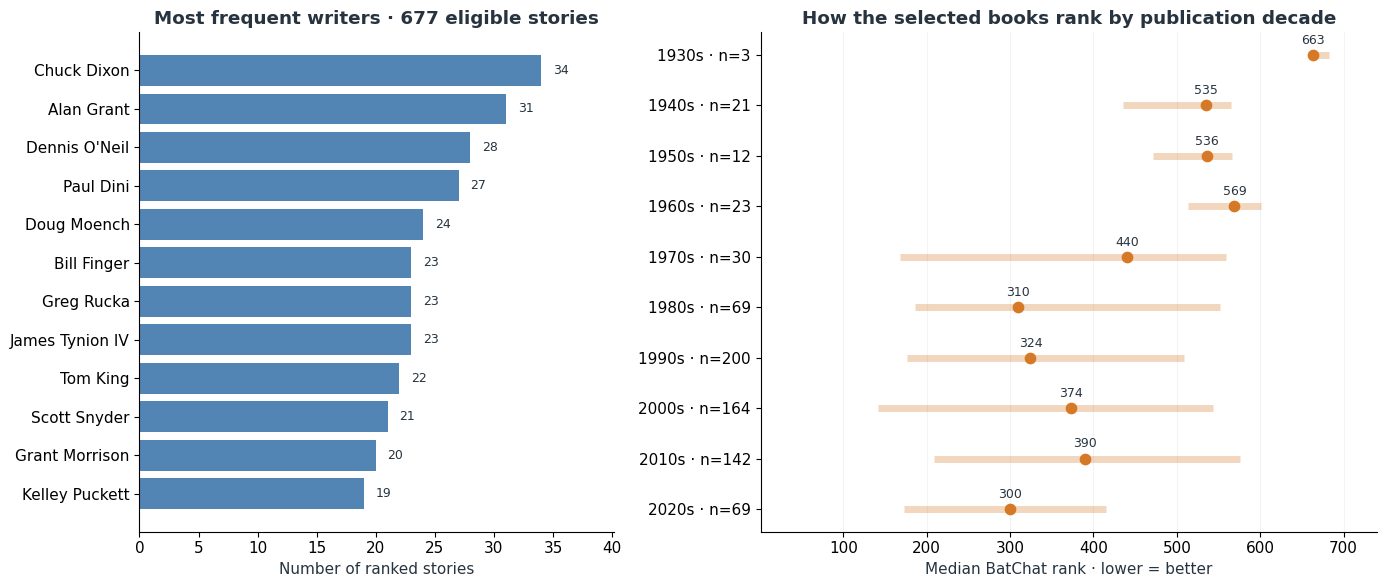

7 stories have no cover-start year. Bars on the right show the middle half, not confidence intervals.


In [2]:
writer_ids=s.loc[s.metadata_complete & s.substory_attribution_coverage.eq(1)
                 & s.narrative_credit_issue_coverage.eq(1),'story_id']
writer_links=credits[credits.credit_scope.eq('selected_narrative') & credits.role.eq('writers')
                     & credits.story_id.isin(writer_ids)]
assert not writer_links.duplicated(['story_id','creator_id']).any()
writer_profiles=writer_links.merge(s[['story_id','rank']],on='story_id',validate='many_to_one').groupby('creator_id').agg(
    readings=('story_id','nunique'),median_rank=('rank','median'))
writer_profiles=writer_profiles.merge(creators[['creator_id','name']],on='creator_id',validate='one_to_one')
writer_profiles=writer_profiles.sort_values(['readings','name'],ascending=[False,True])
writer_profiles.to_csv(REPORT/'writer_profiles.csv',index=False)
frequent=writer_profiles.head(12).iloc[::-1]

era=s.dropna(subset=['cover_year_start']).copy()
era['decade']=(era.cover_year_start//10*10).astype(int)
era_profile=era.groupby('decade')['rank'].agg(n='size',median_rank='median',
    q25=lambda v:v.quantile(.25),q75=lambda v:v.quantile(.75))
assert era_profile.n.sum()+s.cover_year_start.isna().sum()==N
era_profile.to_csv(REPORT/'rank_by_publication_decade.csv')
fig,axes=plt.subplots(1,2,figsize=(14,6),gridspec_kw={'width_ratios':[1,1.3]})
ax=axes[0]
ax.barh(frequent.name,frequent.readings,color=COLORS['blue'],alpha=.8)
for pos,count in enumerate(frequent.readings):ax.text(count+1,pos,str(count),va='center',fontsize=9)
ax.set(xlim=(0,frequent.readings.max()*1.18),xlabel='Number of ranked stories',
       title=f'Most frequent writers · {writer_links.story_id.nunique()} eligible stories')
ax=axes[1]
positions=np.arange(len(era_profile))
ax.hlines(positions,era_profile.q25,era_profile.q75,lw=5,alpha=.3,color=COLORS['orange'])
ax.scatter(era_profile.median_rank,positions,color=COLORS['orange'],s=55)
ax.set(yticks=positions,yticklabels=[f'{d}s · n={int(row.n)}' for d,row in era_profile.iterrows()],
       xlim=(1,N),xlabel='Median BatChat rank · lower = better',title='How the selected books rank by publication decade')
ax.invert_yaxis()
for pos,value in enumerate(era_profile.median_rank):ax.annotate(f'{value:.0f}',(value,pos),xytext=(0,8),textcoords='offset points',ha='center',fontsize=9)
ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
fig.tight_layout();save_figure(fig,REPORT,'eda-writers-and-decades')
print(f'{s.cover_year_start.isna().sum()} stories have no cover-start year. Bars on the right show the middle half, not confidence intervals.')

## Which heroes and villains turn up in the better books?

Barbara Gordon's **52 featured appearances** have a median rank of **235.5**. Bruce Wayne's **479** have **379**. Many of these stories feature both characters.

The figure shows the **15 most frequent names in each role**. Dots mark median ranks, and bars span the middle half of the stories. **Farther left means better ranked.** The dotted line marks the median of all **682** stories with sufficiently complete character records.

The source calls the left-hand role *featured*. It usually means the hero, but villains get their own stories too. The right-hand panel follows antagonists. A character can appear in both panels depending on what they do in a particular story.

For the bigger picture, open the [full Gotham cast atlas](../reports/figures/eda-gotham-atlas.png). It includes **75 featured names and 95 antagonist names** with at least five stories each. A dark patch shows where a character's books cluster in the ranking. A broad spread means they turn up in favorites and disappointments alike. Check the counts: five stories provide less evidence than fifty.

<details><summary>Character records and aliases</summary>

We use stories with complete character records and resolved selections within multi-story issues. Explicit mentions, cameos, flashbacks, and depictions are excluded. Each character counts once per story in each role.

Identical canonical names are combined across universe labels. Other aliases remain separate: Riddler records can use Edward Nashton, Edward Nygma, or Edward Nigma. Groups and unnamed characters remain in the tables too.

</details>

The expandable tables include all **531 featured names** and **1,487 antagonist names**, even those appearing only once. The [featured-cast table](../reports/featured_cast_profiles.csv) and [antagonist table](../reports/antagonist_profiles.csv) include each one's best- and worst-ranked story.

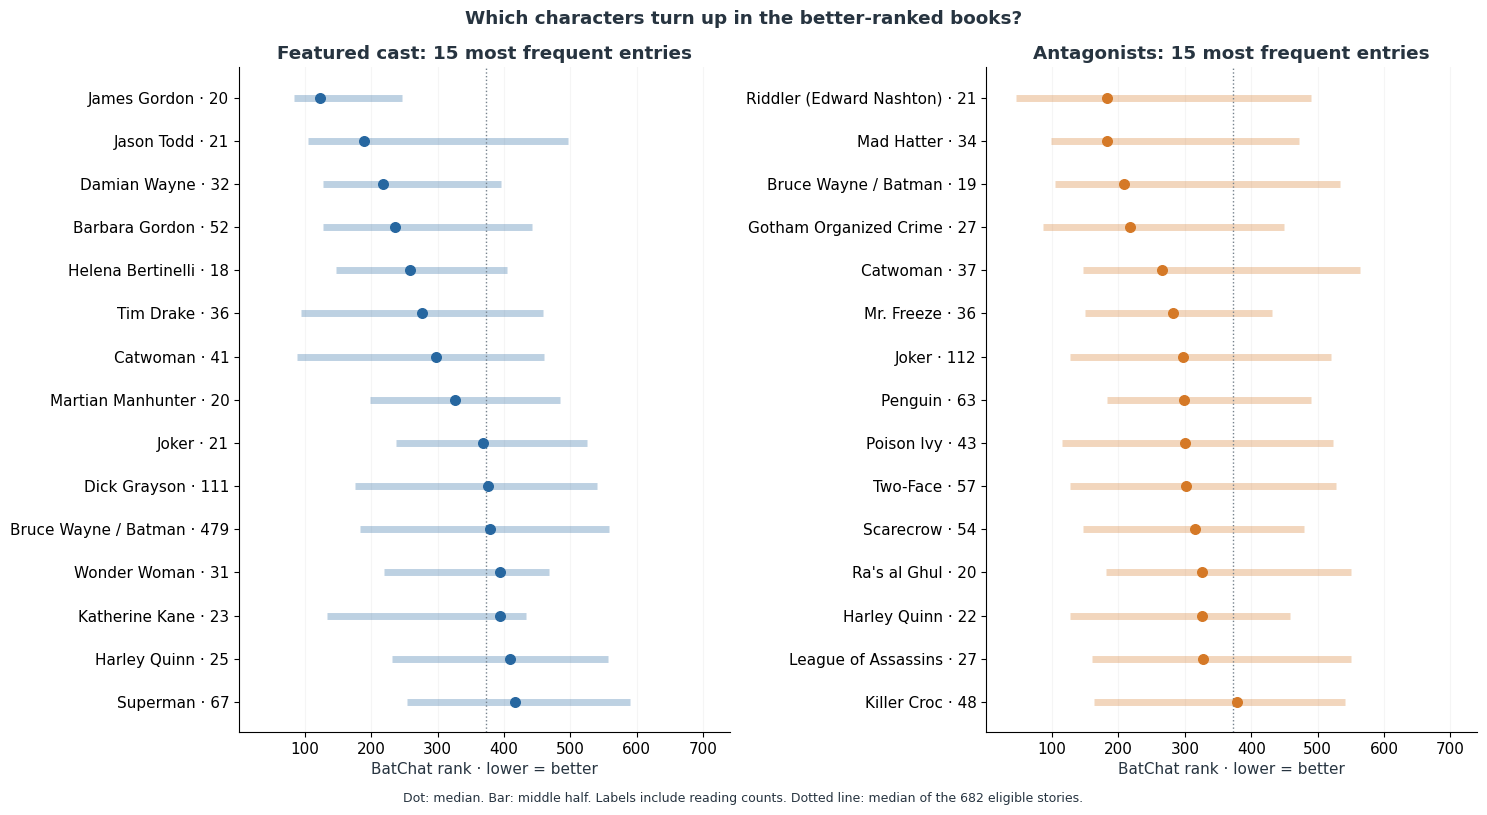

Cast entry,Stories,Median rank · lower = better,Best rank · lowest,Worst rank · highest
Norman McCay,1,13.0,13,13
Josephine MacDonald,2,18.0,12,24
Challengers of the Unknown,1,19.0,19,19
Clay,1,19.0,19,19
Flying Cloud,1,19.0,19,19
Gunner MacKay,1,19.0,19,19
John Wilson,1,19.0,19,19
Kyle Morgan,1,19.0,19,19
Lester Davis,1,19.0,19,19
Losers,1,19.0,19,19


Cast entry,Stories,Median rank · lower = better,Best rank · lowest,Worst rank · highest
Branden,1,1.0,1,1
Gillian B. Loeb,1,1.0,1,1
Johnny Viti,1,1.0,1,1
Carla Falcone,1,4.0,4,4
Donald Sullivan,1,4.0,4,4
Frankie Carbone,1,4.0,4,4
Jimmy Murphy,1,4.0,4,4
Joe Bandano,1,4.0,4,4
Kevin Kelly,1,4.0,4,4
Luca Mareli,1,4.0,4,4


1,104 antagonist entries appear only once. CSVs also include best- and worst-ranked story titles.


In [3]:
import re
clean=s[s.cast_scope.eq('selected_narratives') & s.cast_issue_coverage.eq(1)].copy()
clean['decade']=(clean.cover_year_start//10*10).astype('Int64')

def entity_associations(frame,column):
    out=frame[['story_id','rank','preference','cover_year_start',column]].copy()
    out['entity']=out[column].map(split_set)
    out=out.explode('entity').dropna(subset=['entity'])
    out['entity']=out.entity.str.replace(r' \([^()]+\)$','',regex=True)
    return out.drop_duplicates(['story_id','entity'])

antagonists=entity_associations(clean,'antagonists_entity_ids')
featured=entity_associations(clean,'featured_entity_ids')
aliases={'Jervis Tetch':'Mad Hatter','Selina Kyle':'Catwoman','Victor Fries':'Mr. Freeze',
    'Oswald Cobblepot':'Penguin','Pamela Isley':'Poison Ivy','Harvey Dent':'Two-Face',
    'Jonathan Crane':'Scarecrow','Harleen Quinzel':'Harley Quinn','Waylon Jones':'Killer Croc',
    'Bruce Wayne':'Bruce Wayne / Batman','Richard Grayson':'Dick Grayson','Kal-El':'Superman',
    'Timothy Drake':'Tim Drake','Diana of Themyscira':'Wonder Woman',"J'onn J'onzz":'Martian Manhunter',
    'Edward Nashton':'Riddler (Edward Nashton)'}
profiles={}
for role,entries,filename in [('Featured cast',featured,'featured_cast_profiles.csv'),
                             ('Antagonists',antagonists,'antagonist_profiles.csv')]:
    examples=entries.merge(s[['story_id','title']],on='story_id',validate='many_to_one').sort_values('rank')
    table=examples.groupby('entity').agg(n=('story_id','size'),median_rank=('rank','median'),
        q25=('rank',lambda v:v.quantile(.25)),q75=('rank',lambda v:v.quantile(.75)),
        best_rank=('rank','first'),best_story=('title','first'),worst_rank=('rank','last'),worst_story=('title','last'))
    table['display_name']=[aliases.get(name,name) for name in table.index]
    table=table.sort_values(['median_rank','n'],ascending=[True,False])
    assert table.index.is_unique and table.n.sum()==len(entries)
    assert table.best_rank.le(table.median_rank).all() and table.worst_rank.ge(table.median_rank).all()
    table.to_csv(REPORT/filename)
    profiles[role]=table
all_antagonists=profiles['Antagonists']
# Preserve the twelve-frequency-selected entries for the sensitivity comparison below.
profile=all_antagonists.nlargest(12,'n').sort_values('median_rank')
family=['Bruce Wayne','Richard Grayson','Barbara Gordon','Cassandra Cain','Timothy Drake','Katherine Kane','Selina Kyle','Terry McGinnis']
family_table=profiles['Featured cast'].loc[profiles['Featured cast'].index.isin(family),['n','median_rank']]

fig,axes=plt.subplots(1,2,figsize=(15,8),sharex=True)
for ax,(role,table),color in zip(axes,profiles.items(),[COLORS['blue'],COLORS['orange']]):
    shown=table.nlargest(15,'n').sort_values('median_rank')
    positions=np.arange(len(shown))
    ax.hlines(positions,shown.q25,shown.q75,color=color,lw=5,alpha=.3)
    ax.scatter(shown.median_rank,positions,color=color,s=48,zorder=3)
    ax.axvline(clean['rank'].median(),ls=':',color=COLORS['grey'],lw=1)
    ax.set(yticks=positions,yticklabels=[f'{row.display_name} · {int(row.n)}' for _,row in shown.iterrows()],
        xlim=(1,N),xlabel='BatChat rank · lower = better',title=f'{role}: 15 most frequent entries')
    ax.invert_yaxis();ax.xaxis.grid(True,alpha=.12);ax.set_axisbelow(True)
fig.suptitle('Which characters turn up in the better-ranked books?',fontweight='bold')
fig.text(.5,-.01,f'Dot: median. Bar: middle half. Labels include reading counts. Dotted line: median of the {len(clean)} eligible stories.',ha='center',fontsize=9)
fig.tight_layout();save_figure(fig,REPORT,'craft-antagonists')

# A full-size atlas is exported separately so the article stays readable.
fig,axes=plt.subplots(1,2,figsize=(16,27),gridspec_kw={'wspace':.65})
bins=np.linspace(.5,N+.5,11)
max_rows=max(table.n.ge(5).sum() for table in profiles.values())
for ax,(role,table),entries in zip(axes,profiles.items(),[featured,antagonists]):
    shown=table[table.n.ge(5)]
    histogram=np.vstack([np.histogram(entries.loc[entries.entity.eq(name),'rank'],bins=bins)[0]
                         for name in shown.index])
    assert np.array_equal(histogram.sum(axis=1),shown.n.to_numpy())
    shares=histogram/shown.n.to_numpy()[:,None]
    assert np.allclose(shares.sum(axis=1),1)
    im=ax.imshow(shares,aspect='auto',cmap='Blues',vmin=0,vmax=1,interpolation='nearest')
    ax.set(yticks=np.arange(len(shown)),yticklabels=[f'{row.display_name} · n={int(row.n)}' for _,row in shown.iterrows()],
        xticks=[-.5,2,4.5,7,9.5],xticklabels=['1','185','370','555','740'],
        xlabel='Story rank · best at left',title=f'{role} · {len(shown)} entries with 5+ stories',ylim=(max_rows-.5,-.5))
    ax.tick_params(axis='y',labelsize=8);ax.tick_params(axis='x',top=True,labeltop=True)
fig.suptitle('Gotham cast atlas: where each character’s stories fall',fontsize=17,y=.995,fontweight='bold')
fig.text(.5,.974,'Rows are sorted by median story rank. Each row totals 100%. A dark cell means many of that entry’s stories fall in that rank band.',ha='center',fontsize=10)
cax=fig.add_axes([.35,.025,.3,.008]);fig.colorbar(im,cax=cax,orientation='horizontal',label='Share of this entry’s stories in the band · darker = more stories, not better ranks',ticks=[0,.25,.5,.75,1])
fig.subplots_adjust(top=.95,bottom=.07,left=.15,right=.98)
fig.savefig(REPORT/'figures/eda-gotham-atlas.png',dpi=160,bbox_inches='tight')
plt.close(fig)

from IPython.display import HTML
for role,table in profiles.items():
    shown=table[['display_name','n','median_rank','best_rank','worst_rank']].rename(columns={
        'display_name':'Cast entry','n':'Stories','median_rank':'Median rank · lower = better','best_rank':'Best rank · lowest','worst_rank':'Worst rank · highest'})
    display(HTML(f'<details><summary>All {len(shown):,} {role.lower()} entries, sorted by median story rank — lower is better</summary>'
        '<p>Includes groups and unnamed characters. One-story entries inherit that story’s rank. Source roles describe a particular story, not permanent hero/villain identities.</p>'
        +shown.to_html(index=False,float_format=lambda x:f'{x:.1f}',escape=True)+'</details>'))
print(f'{all_antagonists.n.eq(1).sum():,} antagonist entries appear only once. CSVs also include best- and worst-ranked story titles.')


### The Mad Hatter result deserves an audit

Mad Hatter appears in **34 stories** with a median rank of **183.5**. That isn't first place among every villain: Edward Nashton, one of the Riddler's source names, has a median of **183** across **21 stories**.

Here are some of those books:

| Story | BatChat rank · 1 is best | Issues listing Hatter as an antagonist |
|---|---:|---:|
| *The Long Halloween* | 4 | 3 of 13 |
| *Dark Victory* | 16 | 2 of 14 |
| *Final Crisis* | 26 | 1 of 13 |
| *Unknowing* | 142 | 3 of 3 |
| *Madness* | 164 | 1 of 1 |
| *The Scoop of the Century* | 478 | 1 of 1 |
| *Mad* | 733 | 6 of 6 |

We checked the source entries for all 34 stories. Hatter belongs in the list, but his small role in *Final Crisis* counts just as much as his central role in *Mad*. This is why “stories featuring Mad Hatter” is a useful description and “how much the hosts like Mad Hatter” is a leap.

Even restricting the count to books where he appears as an antagonist in every issue leaves **11 stories**, with a median of **183**. *Unknowing* and *Madness* give us well-ranked, Hatter-centered examples; *Mad* gives us a spectacularly low-ranked one. The [full audit](../reports/hatter_credit_audit.csv) links every source and records how many issues include him.

### Does the villain pattern survive a fairer comparison?

Perhaps a villain's books rank well because they come from a favored era, or because they tend to be short. We can check those two possibilities by comparing stories from the same decade and of similar length.

The next figure follows the **twelve most frequent antagonists**. Orange dots show the average rank difference before grouping by decade and length; blue dots show it afterward. Both calculations use the same books.

**A negative gap means the stories with that antagonist rank better on average.** Each label gives the number of stories included. Some lose a lot of examples when we require comparable books: the League of Assassins keeps only **12 of 26**.

<details><summary>How the comparison works</summary>

Lengths are grouped into 1, 2–4, and 5+ issues. Each decade/length group needs at least three stories with the antagonist and three without. We average the differences within those groups, weighting by the number of stories with that antagonist.

Creators, other characters, and the podcast's selections remain uncontrolled. These are descriptive comparisons without confidence intervals, not significance tests.

</details>

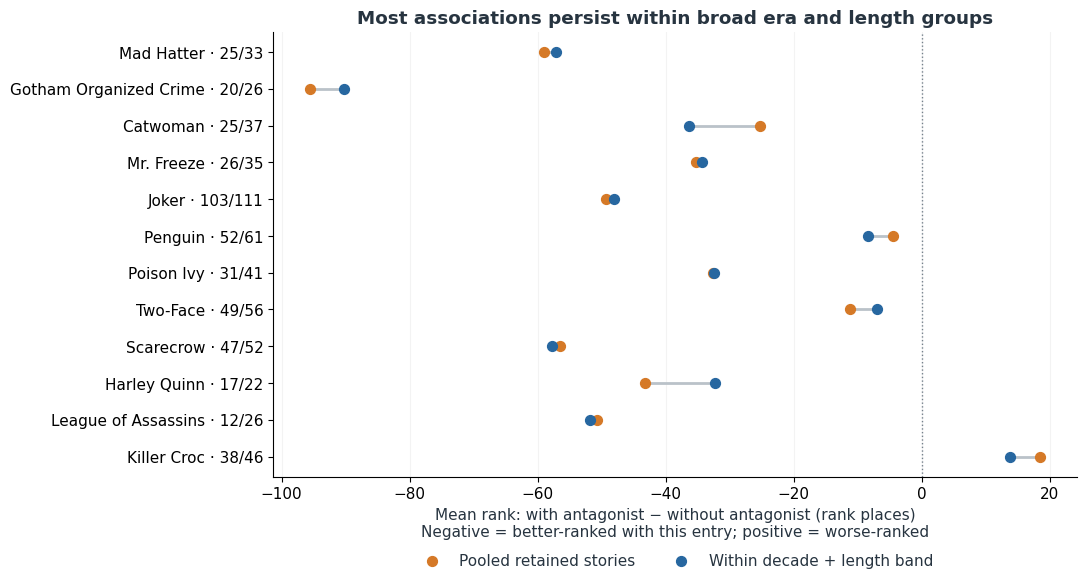

In [4]:
comparison=clean.dropna(subset=['decade']).copy()
comparison['length_band']=pd.cut(comparison.issue_count,[0,1,4,np.inf],labels=['1 issue','2–4 issues','5+ issues'])
comparison=comparison.dropna(subset=['length_band'])
comparisons=[]
for name in profile.index:
    present_ids=set(antagonists.loc[antagonists.entity.eq(name),'story_id'])
    sample=comparison.assign(present=comparison.story_id.isin(present_ids))
    retained=[];gaps=[];weights=[]
    for _,chunk in sample.groupby(['decade','length_band'],observed=True):
        present=chunk.loc[chunk.present,'rank'];absent=chunk.loc[~chunk.present,'rank']
        if len(present)>=3 and len(absent)>=3:
            retained.append(chunk);gaps.append(present.mean()-absent.mean());weights.append(len(present))
    if not retained:continue
    matched=pd.concat(retained)
    assert matched.story_id.is_unique and matched.present.sum()==sum(weights)
    within_gap=np.average(gaps,weights=weights)
    assert min(gaps)<=within_gap<=max(gaps)
    comparisons.append({'entity':name,'available_readings':int(sample.present.sum()),
        'retained_readings':int(matched.present.sum()),'comparison_readings':int((~matched.present).sum()),
        'strata':len(retained),'pooled_gap':matched.loc[matched.present,'rank'].mean()-matched.loc[~matched.present,'rank'].mean(),
        'within_decade_length_gap':within_gap})
character_check=pd.DataFrame(comparisons).set_index('entity').reindex(profile.index)
assert character_check.notna().all().all()
character_check.to_csv(REPORT/'antagonist_within_era_length.csv')
fig,ax=plt.subplots(figsize=(11,6))
for pos,(name,row) in enumerate(character_check.iterrows()):
    ax.plot([row.pooled_gap,row.within_decade_length_gap],[pos,pos],color='#BAC2C9',lw=2)
ax.scatter(character_check.pooled_gap,range(len(character_check)),color=COLORS['orange'],label='Pooled retained stories',s=50,zorder=3)
ax.scatter(character_check.within_decade_length_gap,range(len(character_check)),color=COLORS['blue'],label='Within decade + length band',s=50,zorder=3)
ax.axvline(0,color=COLORS['grey'],ls=':',lw=1)
ax.set(yticks=range(len(character_check)),yticklabels=[f'{aliases.get(name,name)} · {int(row.retained_readings)}/{int(row.available_readings)}' for name,row in character_check.iterrows()],
    xlabel='Mean rank: with antagonist − without antagonist (rank places)\nNegative = better-ranked with this entry; positive = worse-ranked',
    title='Most associations persist within broad era and length groups')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),ncol=2,frameon=False)
fig.tight_layout();save_figure(fig,REPORT,'eda-antagonists-within-era')


Stories featuring Hatter or Scarecrow still average about **57–58 places** better. Joker's difference is **48**. Penguin and Two-Face are much closer to zero, at roughly **8 and 7**.

Grouping by decade and length barely moves most of these comparisons. Particular writers, artists, or runs could still explain the differences.

## Older books don't get an automatic nostalgia bonus

Are older stories treated more fondly? Of **718** stories with enough date information, those discussed within four years of publication have a median rank of **290**. Stories at least fifty years old have **538.5**. The ages in between do not follow a steady trend.

That is hardly a simple nostalgia bonus. It also depends on which old books get discussed. A podcast can revisit a classic, dig up a curiosity, or choose something gloriously strange. Age alone does not tell us why the hosts picked it.

Here, age means the discussion year minus the earliest cover year. It measures the book's age at discussion.

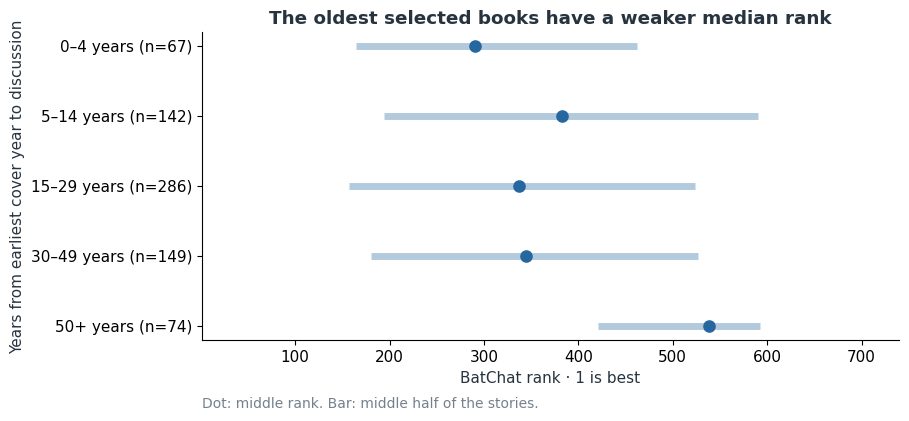

In [5]:
age=s[s.metadata_complete & s.cover_age_year_proxy.notna()].copy()
age['age_band']=pd.cut(age.cover_age_year_proxy,[-1,4,14,29,49,120],
                       labels=['0–4','5–14','15–29','30–49','50+'])
assert age.age_band.notna().all()
age_profile=age.groupby('age_band',observed=True)['rank'].agg(
    n='size',median='median',q25=lambda x:x.quantile(.25),q75=lambda x:x.quantile(.75))
age_profile.to_csv(REPORT/'publication_age_profile.csv')

fig,ax=plt.subplots(figsize=(9,4))
y=np.arange(len(age_profile))
ax.hlines(y,age_profile.q25,age_profile.q75,color=COLORS['blue'],linewidth=5,alpha=.35)
ax.scatter(age_profile['median'],y,color=COLORS['blue'],s=65,zorder=3)
ax.set_yticks(y,[f'{band} years (n={int(row.n)})' for band,row in age_profile.iterrows()])
ax.invert_yaxis()
ax.set(xlim=(1,N),xlabel='BatChat rank · 1 is best',ylabel='Years from earliest cover year to discussion',
       title='The oldest selected books have a weaker median rank')
ax.text(0,-.22,'Dot: middle rank. Bar: middle half of the stories.',
        transform=ax.transAxes,fontsize=10,color=COLORS['grey'])
save_figure(fig,REPORT,'craft-publication-age')

## Is that a young writer—or an older era?

Stories by writers under 30 have a median rank of **484**. Before concluding that Batman needs a more experienced writer, split those books by decade.

The **ten** from the **1940s** have a median of **543**. The **ten** from the **1980s** have **141.5**. Same age bracket, very different Batman comics.

Darker blue marks a better median in the heatmap. Every cell gives its sample size; grey means fewer than **five** stories, so we don't show a median. Read down a column to follow the same age group through different decades. Then look across a row to compare ages within an era.

A writer's age comes bundled with the period, the assignment, and the rest of their career. One overall “best age” would hide more than it explains.

<details><summary>How writer ages are calculated</summary>

The chart includes **512** stories with complete issue lists and known ages for all their writers. Co-written stories use the median writer age. Each person's age is calculated from the years of the issues they wrote. These are calendar-year differences, not exact ages on publication day.

</details>

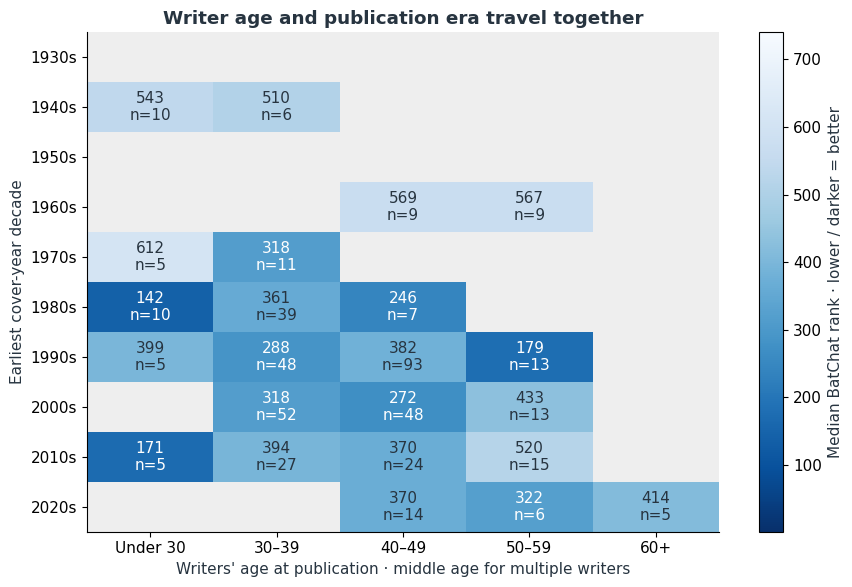

In [6]:
assert creators.creator_id.is_unique
assert not credits.duplicated(['story_id','creator_id','role','credit_scope']).any()
people=credits[credits.credit_scope.eq('selected_narrative')].merge(
    creators[['creator_id','name','gender','entity_type','eisner_personal_win_count_observed']],
    on='creator_id',validate='many_to_one')
people=people[~people.entity_type.isin(['organization','collective'])]
# Count unique creators within each role; repeat readings do not multiply this table.
unique_people=people.drop_duplicates(['role','creator_id'])
gender_by_role=pd.crosstab(unique_people.role,unique_people.gender.fillna('unreported'))

gender_by_role.to_csv(REPORT/'creator_gender_by_role.csv')
writer_age=credits[credits.credit_scope.eq('selected_narrative') & credits.role.eq('writers')].groupby('story_id').agg(
    writers=('creator_id','size'),known_ages=('age_at_publication_year_proxy','count'),
    age=('age_at_publication_year_proxy','median'))
writer_age=writer_age[writer_age.writers.eq(writer_age.known_ages)].merge(
    s[['story_id','rank','cover_year_start','metadata_complete','narrative_credit_issue_coverage']],
    on='story_id',validate='one_to_one')
writer_age=writer_age[writer_age.metadata_complete & writer_age.narrative_credit_issue_coverage.eq(1)]
writer_age['age_band']=pd.cut(writer_age.age,[-1,29,39,49,59,110],
                              labels=['Under 30','30–39','40–49','50–59','60+'])
writer_age['decade']=(writer_age.cover_year_start//10*10).astype(int)
profile=writer_age.groupby(['decade','age_band'],observed=True)['rank'].agg(n='size',median='median')
profile.to_csv(REPORT/'writer_age_by_decade.csv')

medians=profile['median'].unstack('age_band');counts=profile.n.unstack('age_band')
fig,ax=plt.subplots(figsize=(9,6))
values=medians.where(counts.ge(5))
image=ax.imshow(values.to_numpy(dtype=float),vmin=1,vmax=N,cmap='Blues_r',aspect='auto')
ax.set_facecolor('#EEEEEE')
ax.set_xticks(range(len(values.columns)),values.columns)
ax.set_yticks(range(len(values.index)),[f'{v}s' for v in values.index])
for row in range(len(values)):
    for col in range(len(values.columns)):
        if pd.notna(values.iloc[row,col]):
            ax.text(col,row,f'{values.iloc[row,col]:.0f}\nn={int(counts.iloc[row,col])}',
                    ha='center',va='center',color='white' if values.iloc[row,col]<350 else '#273440')
ax.set(xlabel="Writers' age at publication · middle age for multiple writers",ylabel='Earliest cover-year decade',
       title='Writer age and publication era travel together')
fig.colorbar(image,ax=ax,label='Median BatChat rank · lower / darker = better')
fig.tight_layout();save_figure(fig,REPORT,'craft-writer-age-era')

<details><summary>Checking the creator biographies</summary>

The creator table has **933** birth years and **1,685** sourced gender labels. Gender comes from current wiki records; it is not guessed from names or assumed to describe someone at publication time.

Counting people gives a different picture from counting stories. The selected stories include **53** colorists and **49** writers recorded as female. Adrienne Roy alone appears on **75** stories.

The records also include **sixteen** verified organizations. These have no personal ages or personal awards. For example, Heroic Age's staff template puts its founding year in a birth-year field; treating it as a person would invent a very young colorist.

The **311** creator–award links include event years so that analyses can exclude prizes won after publication.

</details>

## Same writer, different artist—and different comic

Here are *Red Rain* at **#6** and *Unseen* at **#716**, both by Doug Moench and Kelley Jones. 

The chart follows two writers across two artists each. Dots show individual books; bars show medians. Even the same partnership can produce favorites and disappointments.

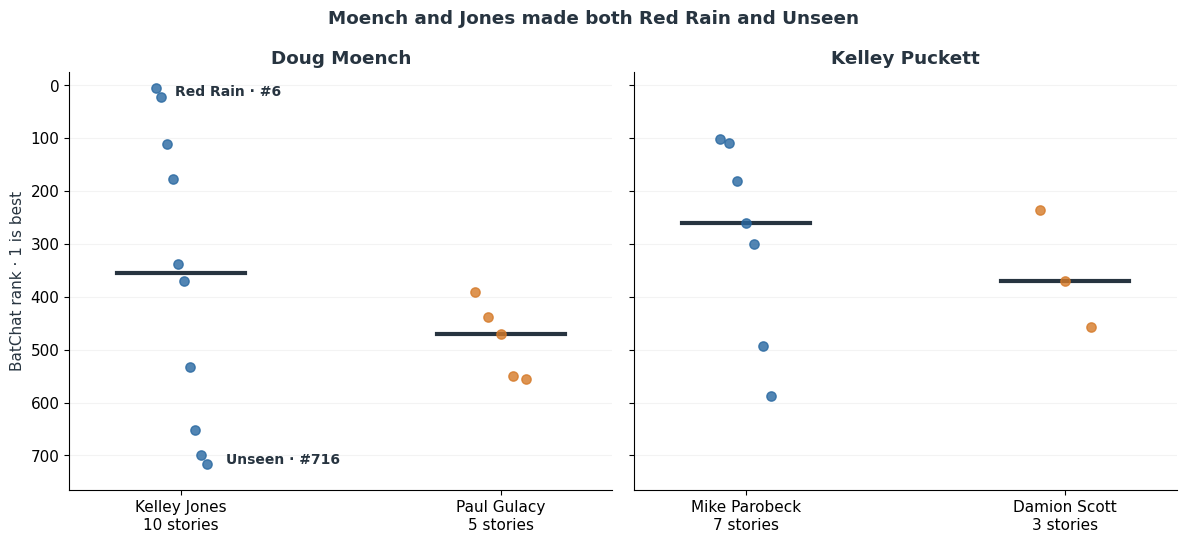

In [7]:
single=s[s.narrative_writers.map(split_set).map(len).eq(1)&s.narrative_pencilers.map(split_set).map(len).eq(1)
         &s.narrative_credit_issue_coverage.eq(1)].copy()
pairs=[('Doug Moench','Kelley Jones'),('Doug Moench','Paul Gulacy'),('Kelley Puckett','Mike Parobeck'),('Kelley Puckett','Damion Scott')]
rows=[]
for writer,artist in pairs:
    found=single[single.narrative_writers.eq(writer)&single.narrative_pencilers.eq(artist)]
    cast=entity_associations(found,'featured_entity_ids').entity.value_counts().head(3)
    rows.append({'writer':writer,'artist':artist,'n':len(found),'median_rank':found['rank'].median(),
                 'cover_years':f'{found.cover_year_start.min():.0f}–{found.cover_year_end.max():.0f}',
                 'frequent_featured_entities':'; '.join(cast.index)})
partnerships=pd.DataFrame(rows)
partnerships.to_csv(REPORT/'creative_partnerships.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,5.5),sharey=True)
for ax,writer in zip(axes,['Doug Moench','Kelley Puckett']):
    artist_labels=[]
    for pos,(_,artist) in enumerate([p for p in pairs if p[0]==writer]):
        found=single.loc[single.narrative_writers.eq(writer)&single.narrative_pencilers.eq(artist)].sort_values('rank')
        values=found['rank'].to_numpy()
        x=pos+np.linspace(-.08,.08,len(values))
        ax.scatter(x,values,s=45,alpha=.8,color=[COLORS['blue'],COLORS['orange']][pos],zorder=3)
        if len(values):ax.plot([pos-.2,pos+.2],[np.median(values)]*2,color='#273440',lw=3)
        artist_labels.append(f'{artist}\n{len(values)} stories')
        if artist=='Kelley Jones':
            for k,label,offset in [(0,'Red Rain · #6',(14,-2)),(-1,'Unseen · #716',(14,3))]:
                ax.annotate(label,(x[k],values[k]),xytext=offset,textcoords='offset points',
                            fontsize=10,va='center',fontweight='bold')
    ax.set(xticks=[0,1],xticklabels=artist_labels,title=writer,xlim=(-.35,1.35))
    ax.yaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
axes[0].set(ylabel='BatChat rank · 1 is best',ylim=(N+25,-25))
fig.suptitle('Moench and Jones made both Red Rain and Unseen',fontweight='bold')
fig.tight_layout();save_figure(fig,REPORT,'craft-partnerships')

Kelley Puckett's books with Mike Parobeck have a median rank of **261 across seven stories**. With Damion Scott, it is **371 across three**. That sounds like a preference for one artist until we look at what they were making.

Parobeck's books belong to the world of *Batman: The Animated Series*. Scott's include Cassandra Cain's early *Batgirl* stories and her introduction in *No Man's Land*. The artist changes alongside the protagonist and the kind of Batman comic being told. [DC on Batman Adventures](https://www.dc.com/graphic-novels/batman-adventures-1992/batman-adventures-vol-2), [DC on Scott and Cassandra Cain](https://www.dc.com/blog/2023/02/23/power-on-page-six-dc-comics-by-black-creators)

An average labeled “artist quality” would hide those differences.

## Does an arc benefit from keeping its team?

An artist change halfway through an arc can be jarring. Does keeping the same writer and penciler go with better rankings?

Across the qualifying arcs, stable teams have a median rank of **316.5**, versus **340** for changing teams. But longer arcs have more chances to change artists. The three panels compare books of similar length.

At **3–4 issues**, stable teams have a median about **30 places** better. At **5–6 issues**, the difference is **5**. At seven or more, it reverses by **6**. Both groups contain a wide range of ranks. Keeping the same team is no guarantee, and the apparent advantage is much smaller among the longer arcs.

<details><summary>Which arcs qualify?</summary>

We include arcs of at least three issues with complete issue lists. Each issue must select one story, and all writers and pencilers must be known. “Stable” means the same set of writers and pencilers throughout.

</details>

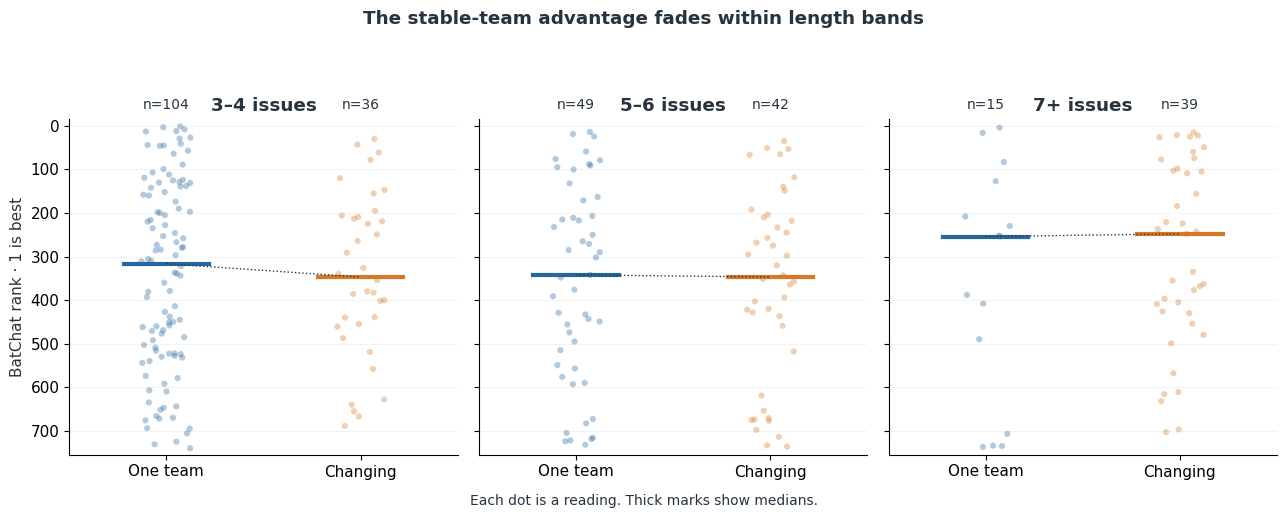

In [8]:
multi_narrative_entries=set(issues.loc[issues.selected_substory_indexes.fillna('').str.contains('|',regex=False),'story_id'])
teams=s[s.issue_count.ge(3) & ~s.story_id.isin(multi_narrative_entries) & s.metadata_complete & s.narrative_credit_issue_coverage.eq(1)].copy()
teams['stable_team']=teams.narrative_dominant_team_share.eq(1)
teams['length_band']=pd.cut(teams.issue_count,[2,4,6,np.inf],labels=['3–4 issues','5–6 issues','7+ issues'])
team_table=teams.groupby(['length_band','stable_team'],observed=True)['rank'].agg(n='size',median_rank='median')
# Keep the full counts and medians in the exported table.
team_table.to_csv(REPORT/'team_stability_by_length.csv')
fig,axes=plt.subplots(1,3,figsize=(13,4.5),sharey=True)
for ax,band in zip(axes,['3–4 issues','5–6 issues','7+ issues']):
    medians=[]
    for pos,(same,color,label) in enumerate([(True,COLORS['blue'],'One team'),(False,COLORS['orange'],'Changing')]):
        values=teams.loc[teams.length_band.eq(band)&teams.stable_team.eq(same),'rank'].sort_values().to_numpy()
        medians.append(np.median(values))
        ax.scatter(pos+np.random.default_rng(42).uniform(-.13,.13,len(values)),values,
                   s=20,alpha=.35,color=color,edgecolors='none')
        ax.plot([pos-.22,pos+.22],[np.median(values)]*2,color=color,lw=3)
        ax.text(pos,1.03,f'n={len(values)}',transform=ax.get_xaxis_transform(),ha='center',fontsize=10)
    ax.plot([0,1],medians,color='#273440',lw=1,ls=':')
    ax.set(xticks=[0,1],xticklabels=['One team','Changing'],xlim=(-.5,1.5),title=band)
    ax.title.set_position((.5,1.12));ax.yaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
axes[0].set(ylim=(N+15,-15),ylabel='BatChat rank · 1 is best')
fig.suptitle('The stable-team advantage fades within length bands',y=1.08,fontweight='bold')
fig.text(.5,-.02,'Each dot is a reading. Thick marks show medians.',ha='center',fontsize=10)
fig.tight_layout();save_figure(fig,REPORT,'craft-team-continuity')


## The familiar names below the headline

Batman fans often describe a run by its writer and artist. The colorists and letterers can connect books across several of those runs. John Costanza and Todd Klein lead our lettering counts; Adrienne Roy leads color.

Across the same **589 stories**, the five most frequent letterers account for **34.6%** of the total for that role. The corresponding share is **18.3%** for writers and **9.5%** for pencilers. For this count, people who share a role split a story's contribution equally.

Letterers and colorists often stay when writers and artists change.

<details><summary>How the shares are counted</summary>

Each story contributes one unit per role. Two writers get half each; five get one fifth each. This keeps anthologies from dominating simply because they have more contributors. All 589 stories have all six roles recorded.

Studios remain in the source records. These percentages describe the names attached to the stories, not working hours or industry market share. They do not establish an effect on rank.

</details>

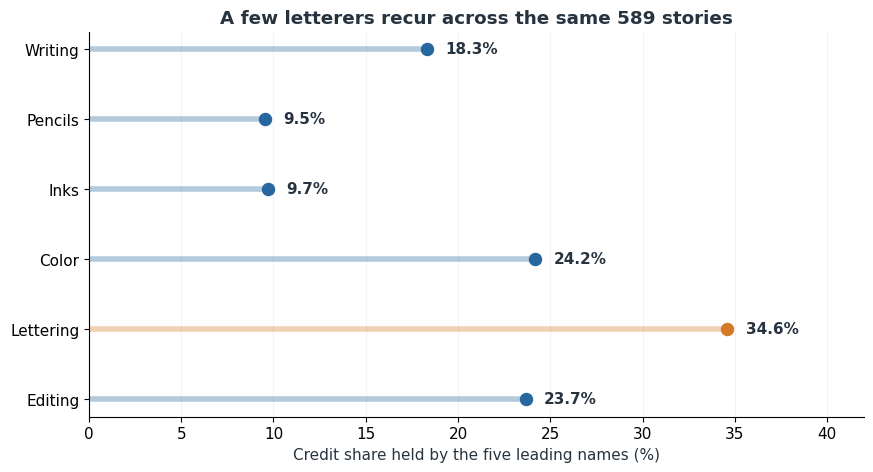

,Name,Stories
Role,,
Editing,Dennis O'Neil,113
Color,Adrienne Roy,66
Lettering,John Costanza,69
Lettering,Todd Klein,67
Writing,Chuck Dixon,33
Writing,Alan Grant,30
Color,Dave Stewart,27
Editing,Scott Peterson,43
Inks,Rick Burchett,17


In [9]:
roles=['writers','pencilers','inkers','colorists','letterers','editors']
complete_ids=s.loc[s.metadata_complete & s.substory_attribution_coverage.eq(1)
                  & s.narrative_credit_issue_coverage.eq(1),'story_id']
role_links=credits[credits.credit_scope.eq('selected_narrative') & credits.story_id.isin(complete_ids)].copy()
common=role_links.groupby('story_id').role.nunique()
role_links=role_links[role_links.story_id.isin(common[common.eq(len(roles))].index)]
assert set(role_links.role)==set(roles)
assert not role_links.duplicated(['story_id','role','creator_id']).any()
role_links['credit_share']=1/role_links.groupby(['story_id','role']).creator_id.transform('size')
assert np.allclose(role_links.groupby(['story_id','role']).credit_share.sum(),1)
credit_counts=role_links.groupby(['role','creator_id']).agg(
    readings=('story_id','nunique'),allocated_credits=('credit_share','sum')).reset_index()
credit_counts=credit_counts.merge(creators[['creator_id','name','entity_type']],on='creator_id',validate='many_to_one')
common_n=role_links.story_id.nunique()
assert role_links.groupby('role').story_id.nunique().eq(common_n).all()
credit_counts['share']=credit_counts.allocated_credits/common_n
leaders=credit_counts.sort_values('share',ascending=False).groupby('role').head(5)
concentration=leaders.groupby('role').share.sum().reindex(roles).rename('top_five_share').to_frame()
concentration['distinct_credit_entities']=credit_counts.groupby('role').size()
concentration['readings']=common_n
concentration.to_csv(REPORT/'credit_concentration_by_role.csv')
credit_counts.to_csv(REPORT/'creator_credit_frequency.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5))
labels={'writers':'Writing','pencilers':'Pencils','inkers':'Inks','colorists':'Color','letterers':'Lettering','editors':'Editing'}
for pos,(role,row) in enumerate(concentration.iterrows()):
    value=row.top_five_share*100
    color=COLORS['orange'] if role=='letterers' else COLORS['blue']
    ax.hlines(pos,0,value,color=color,lw=4,alpha=.35)
    ax.scatter(value,pos,s=75,color=color,zorder=3)
    ax.text(value+1,pos,f'{value:.1f}%',va='center',fontweight='bold')
ax.set(yticks=range(len(roles)),yticklabels=[labels[r] for r in roles],xlim=(0,42),
       xlabel='Credit share held by the five leading names (%)',
       title=f'A few letterers recur across the same {common_n} stories')
ax.invert_yaxis();ax.xaxis.grid(True,alpha=.15);ax.set_axisbelow(True)
save_figure(fig,REPORT,'craft-credit-concentration')
top_names=credit_counts.sort_values('share',ascending=False).groupby('role').head(2)
display(top_names.assign(Role=top_names.role.map(labels)).rename(columns={
    'name':'Name','readings':'Stories'})[['Role','Name','Stories']].set_index('Role'))

## Check the colorist and letterer for Eisners

Does having an Eisner winner on the team go with a better-ranked comic? We count only prizes won before publication, excluding later wins.

Of **557 eligible stories**, **53** have a colorist who had already won an Eisner for that craft. **38** have a previously awarded letterer. Just **22** have a previously awarded writer. The same person can account for many stories, and a book can have winners in several roles.

The left panel shows where those awards sit within the team. The right asks whether stories with award-winning contributors rank better than other stories from the same decade.

<details><summary>Which awards count?</summary>

We count personal craft wins before publication. Same-year prizes are excluded because their timing is ambiguous. The reviewed archive begins in 1988, so earlier books have missing award data. Hall of Fame honors and prizes for particular works or editions stay separate. [Official Eisner archive](https://www.comic-con.org/awards/eisner-awards/past-recipients/past-recipients-1990s/)

</details>

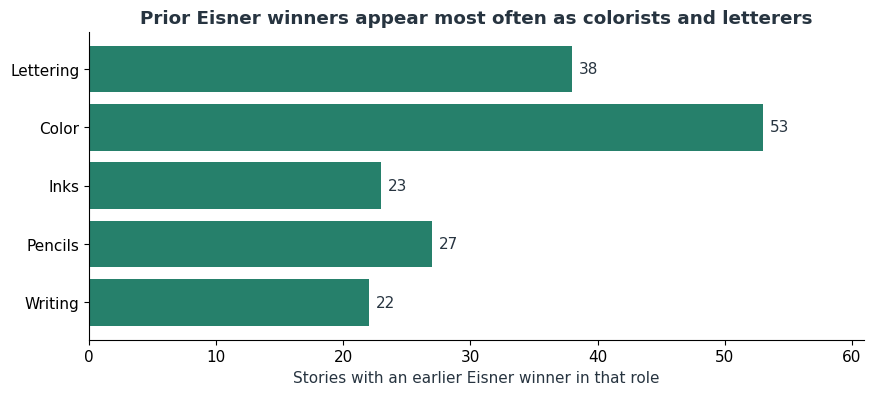

In [10]:
eligible=s[s.creator_eisner_personal_wins_pre_publication.notna() & s.awards_credit_scope.eq('selected_narratives')].copy()
award_roles=['writers','pencilers','inkers','colorists','letterers']
role_counts=pd.DataFrame([{'role':r,'entries_with_prior_role_win':eligible[f'{r}_eisner_role_wins_pre_publication'].gt(0).sum(),
                          'eligible_entries':len(eligible)} for r in award_roles])

fig,ax=plt.subplots(figsize=(10,4))
bars=ax.barh(role_counts.role.map(labels),role_counts.entries_with_prior_role_win,color=COLORS['green'])
ax.bar_label(bars,padding=5)
ax.set_xlim(0,role_counts.entries_with_prior_role_win.max()*1.15)
ax.set(xlabel='Stories with an earlier Eisner winner in that role',title='Prior Eisner winners appear most often as colorists and letterers')
save_figure(fig,REPORT,'craft-award-roles')
role_counts.to_csv(REPORT/'award_role_coverage.csv',index=False)

eligible['decade']=(eligible.cover_year_start//10*10).astype('Int64')
eligible['prior_craft_winner']=eligible.creator_eisner_personal_wins_pre_publication.gt(0)
award_table=eligible.groupby(['decade','prior_craft_winner'])['rank'].agg(n='size',median_rank='median')
award_table.to_csv(REPORT/'award_rank_by_decade.csv')
work_cols=['work_eisner_exact_work_wins','work_eisner_contained_story_wins','work_eisner_collected_edition_wins',
           'work_eisner_series_context_wins','work_eisner_edition_design_wins','work_eisner_archival_edition_wins']
work=s[s[work_cols].sum(axis=1).gt(0)]
# Edition and work awards stay separate from personal craft wins.

The answer changes by decade. In the **2000s**, stories with a prior craft winner have a median rank of **183**, versus **428** without one. In the **2010s**, the medians are **423 and 359**. In the **2020s**, they are **369 and 291.5**. The association reverses.

Awards come with career history and different opportunities. They cannot isolate a person's contribution to a particular book. In the prediction notebook, adding prior awards barely improves the model.

Color suggests a more interesting measurement. Richmond Lewis colored *Year One* twice for different presentations. Miller and Mazzucchelli's story stays the same, but the reader sees a different version of the art. Todd Klein's lettering is part of that visual experience too. [DC on Richmond Lewis](https://www.dc.com/blog/2024/03/29/the-woman-whose-colors-brought-batman-year-one-to-life-twice)

To study that difference, we would need to know which edition the hosts read. The same goes for an Artist's Edition prize: it belongs to that presentation, not the original comic's publication-time award record.

## Twenty pages can mean very different things

How much comic is in a page count? A collection's 200 pages might include covers, extras, and unrelated stories. We checked the actual story length for **17 examples**.

*There Is No Hope in Crime Alley* takes **12 pages**. *Ego* has **62**. *Year One* has **90**. *Three Jokers* has **144** and ranks last. These deliberately chosen examples cannot establish whether longer stories rank better. They do let us compare what creators do with the space.

<details><summary>Where the page counts come from</summary>

The sampled GCD records exclude ads, covers, letters pages, and unrelated backups. Fractional pages are retained: the two ranked Batman #219 stories total **14.17 + 8 = 22.17 pages**. [GCD issue record](https://www.comics.org/issue/23317/)

</details>

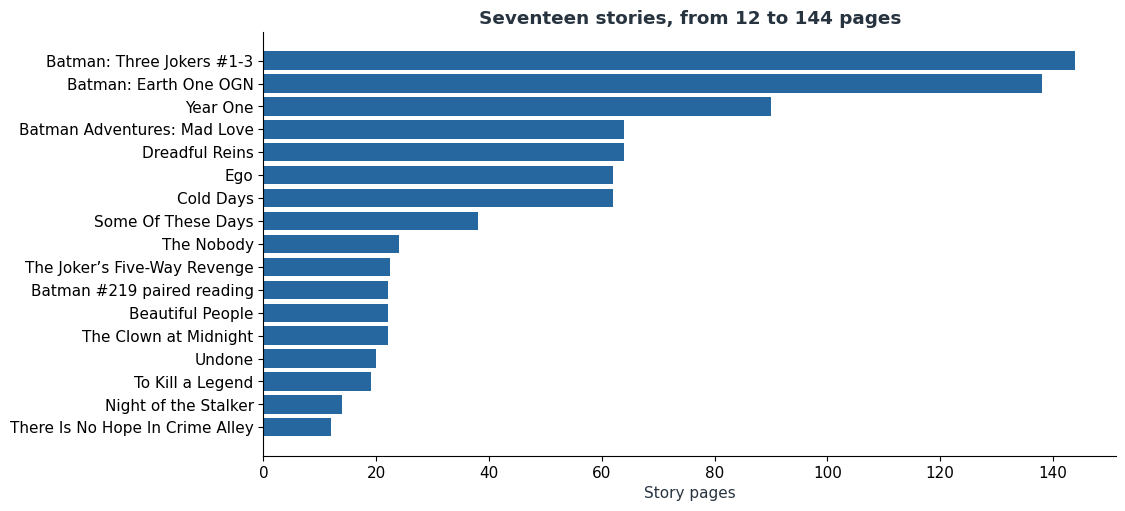

In [11]:
narratives=pd.read_csv(ROOT/'references/catalogue_narratives.csv')
lengths=s[s.gcd_narrative_page_count.notna()][['story_id','title','rank','gcd_narrative_page_count']].copy()

component=narratives[narratives.story_id.eq('806af1982441')][['narrative_title','narrative_page_count','match_scope','catalogue_url']]


forms=s[s.title.isin(['Undone','The Clown at Midnight'])][['title','rank','gcd_narrative_page_count','gcd_story_types','synopsis_opening']].copy()
forms['wiki_excerpt_words']=forms.synopsis_opening.fillna('').str.split().str.len()

fig,ax=plt.subplots(figsize=(11,5.5))
shown=lengths.sort_values('gcd_narrative_page_count')
ax.barh(shown.title.str.replace('Death Casts the Deciding Vote/The Silent Night of Batman','Batman #219 paired reading',regex=False),
        shown.gcd_narrative_page_count,color=COLORS['blue'])
ax.set(xlabel='Story pages',title='Seventeen stories, from 12 to 144 pages')
save_figure(fig,REPORT,'craft-narrative-pages')

*Undone* tells its story in **20 silent pages**. *The Clown at Midnight* uses **22 pages of illustrated prose**. They rank **47th and 85th**. Similar lengths, very different reading experiences. [DC on the silent issue](https://www.dc.com/blog/2013/09/05/5-2-reasons-dc-comics-the-new-52-anniversary-edition)

A wiki summary might describe a silent image at length, then compress pages of dialogue into a sentence. Its length cannot tell us how wordy the comic is.

We have **1,711 full summaries**, totaling **703,219 words**, with no length cap. **587 stories** have some text; **481** have all their selected summaries and complete issue lists. [The text experiment](1.0-batchat-rankings.ipynb#6.-Does-knowing-the-plot-help?) tests whether those summaries help predict rank. Before getting to their vocabulary, here's something they leave out.

### A visual feature the plot summary never sees

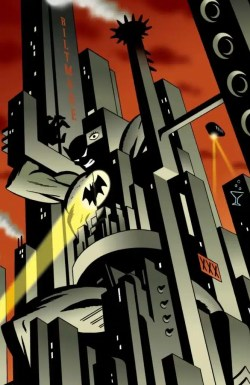

In this *Ego* illustration, Batman almost merges with the city's angular black shapes. The towers dominate the frame. An orange sky separates their silhouettes, while a yellow beam cuts across them and pulls the eye diagonally through the scene.

“Batman above Gotham” would describe the subject and lose most of what makes the image work. Shape, contrast, and composition offer features to study across the actual pages.

*Darwyn Cooke artwork for Ego, © DC. Small image as reproduced by [ComicsXF](https://comicsxf.com/batchat-rankings/); [source image](https://i0.wp.com/www.comicsxf.com/wp-content/uploads/2022/06/batman-ego-666x1024.webp?resize=640%2C984). Included for the visual commentary above.*

In [12]:
texts=pd.read_csv(ROOT/'data/processed/story_texts.csv')
assert not texts.duplicated(['story_id','requested_title','substory_index']).any()
text_profile=texts.groupby('story_id').agg(
    narrative_rows=('text_status','size'),available_synopses=('text_status',lambda v:v.eq('available').sum()),
    available_words=('synopsis_word_count','sum'))
text_profile=text_profile.merge(s[['story_id','title','issue_list_complete']],on='story_id',validate='one_to_one')
text_profile['all_selected_texts_available']=(text_profile.available_synopses.eq(text_profile.narrative_rows)
                                             & text_profile.issue_list_complete)
text_profile.to_csv(REPORT/'synopsis_coverage.csv',index=False)

### The missing plots have an era problem

We have plot text for **67 of 69** stories from the 1980s, but only **23 of 69** from the 2020s. Requiring every selected summary widens the gap: **59** versus **8**.

The green bars show complete coverage, orange partial coverage, and grey no usable text. The numbers count stories. A plot analysis will disproportionately describe older books. A prediction model can also pick up the era from whether text is missing.

<details><summary>What counts as complete?</summary>

Every selected summary must be present, and the issue list must be complete. Partial coverage fails one or both conditions. “No text” includes stories whose selections could not be resolved. Seven stories have no cover-start decade.

The snapshot cannot tell us how much of the gap is documentation lag. The prediction notebook accounts for text availability and length before adding the words themselves.

</details>

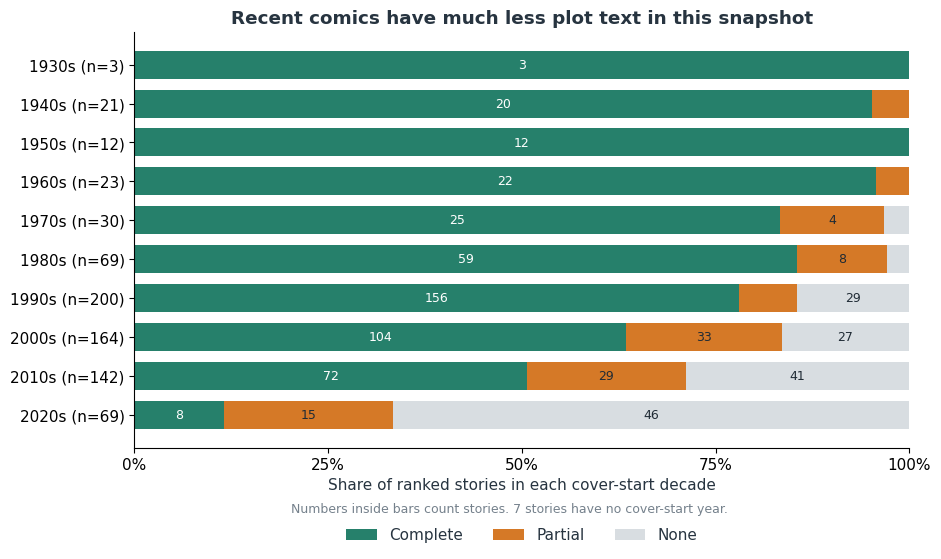

Unknown cover-start decade: 7 stories; 0 have some plot text.


In [13]:
text_era=s[['story_id','cover_year_start']].merge(
    text_profile[['story_id','available_synopses','all_selected_texts_available']],
    on='story_id',how='left',validate='one_to_one')
assert len(text_era)==N and text_era.available_synopses.notna().all()
text_era['decade']=(text_era.cover_year_start//10*10).astype('Int64')
text_era['coverage']=np.select(
    [text_era.all_selected_texts_available,text_era.available_synopses.gt(0)],
    ['Complete','Partial'],default='None')
coverage_order=['Complete','Partial','None']
text_by_era=pd.crosstab(text_era.decade,text_era.coverage).reindex(columns=coverage_order,fill_value=0)
text_by_era['n']=text_by_era.sum(axis=1)
unknown_era=text_era.decade.isna().sum()
assert text_by_era['n'].sum()+unknown_era==N
text_by_era.to_csv(REPORT/'synopsis_coverage_by_decade.csv')
fig,ax=plt.subplots(figsize=(10,5.4))
left=np.zeros(len(text_by_era))
for status,color in zip(coverage_order,[COLORS['green'],COLORS['orange'],'#D8DDE1']):
    width=100*text_by_era[status]/text_by_era['n']
    ax.barh(np.arange(len(text_by_era)),width,left=left,color=color,label=status,height=.72)
    for pos,(share,count) in enumerate(zip(width,text_by_era[status])):
        if share>=9:
            ax.text(left[pos]+share/2,pos,str(count),ha='center',va='center',
                    color='white' if status=='Complete' else '#202B35',fontsize=9)
    left+=width.to_numpy()
ax.set(yticks=np.arange(len(text_by_era)),
       yticklabels=[f'{decade}s (n={int(row.n)})' for decade,row in text_by_era.iterrows()],
       xticks=[0,25,50,75,100],xticklabels=['0%','25%','50%','75%','100%'],xlim=(0,100),
       xlabel='Share of ranked stories in each cover-start decade',
       title='Recent comics have much less plot text in this snapshot')
ax.invert_yaxis()
ax.legend(loc='upper center',bbox_to_anchor=(.5,-.16),ncol=3,frameon=False)
fig.text(.5,-.01,f'Numbers inside bars count stories. {unknown_era} stories have no cover-start year.',
         ha='center',fontsize=9,color=COLORS['grey'])
save_figure(fig,REPORT,'craft-synopsis-coverage')

print(f'Unknown cover-start decade: {unknown_era} stories; '
      f'{text_era.loc[text_era.decade.isna(),"available_synopses"].gt(0).sum()} have some plot text.')

### Gotham, in a few hundred words

What does a Batman plot sound like once we take out “Batman”?

The bat collects words from the **481 stories with every selected summary available**. Larger words occur in more stories. Repeating a word a hundred times in one summary still counts once.

We show up to **120** words after removing English stopwords, common connecting words, and a fixed list of character and setting names. The code lists the exclusions. Different word forms stay separate. **Neither this cloud nor the villain clouds use rankings or ratings.**

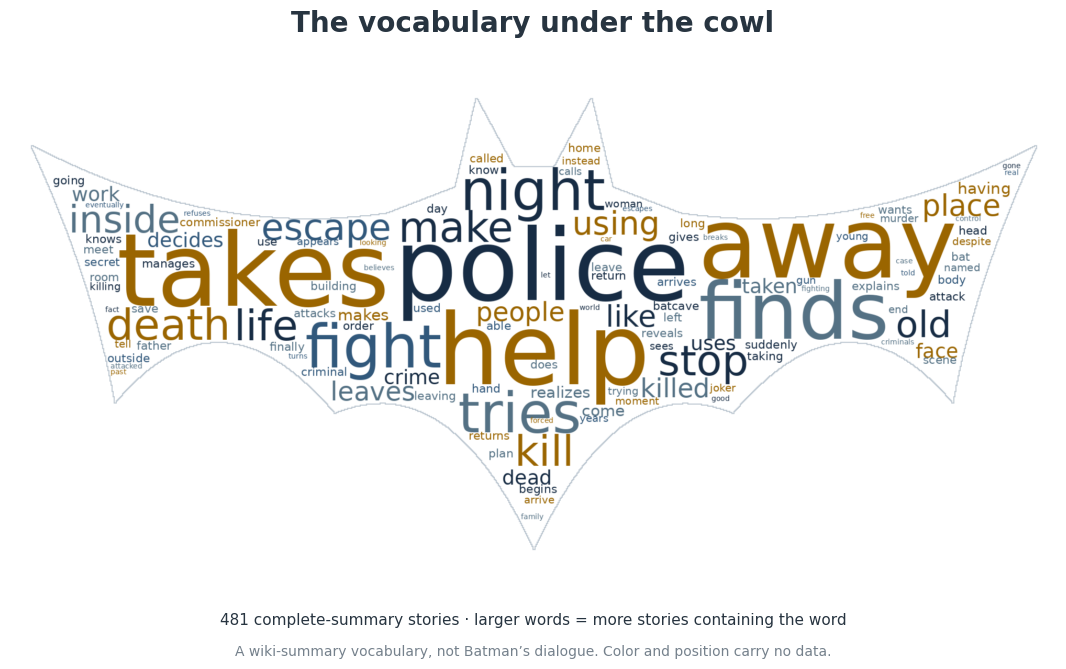

In [14]:
from matplotlib.font_manager import findfont
from matplotlib.path import Path as ShapePath
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw, ImageFont
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from wordcloud import WordCloud
from scripts.analysis import plot_documents

plot_docs = plot_documents(s, texts)
cloud_docs = plot_docs.loc[plot_docs.plot_complete.eq(1)].reset_index(drop=True)
# Keep names from answering the character comparison before it starts.
extra_stopwords = set("""batman bruce wayne gotham city robin dick grayson tim drake
    jason todd alfred gordon riddler edward nashton nigma nygma penguin oswald cobblepot
    tells says asks comes goes gets just later soon new man men time way back
    couldn didn doesn isn wasn wouldn don ve ll aren weren hasn hadn haven shouldn needn mustn mightn won shan""".split())
vectorizer = CountVectorizer(binary=True, min_df=3,
    stop_words=sorted(ENGLISH_STOP_WORDS | extra_stopwords),
    token_pattern=r'(?u)\b[a-zA-Z]{3,}\b')
word_presence = vectorizer.fit_transform(cloud_docs.plot_text)
terms = vectorizer.get_feature_names_out()
word_counts = word_presence.sum(axis=0).A1
assert cloud_docs.story_id.is_unique and set(word_presence.data) == {1}
assert word_counts.max() <= len(cloud_docs)

# Original geometric silhouettes; no downloaded logo or comic art.
bat_outline = ShapePath(
    [(20,90),(190,180),(360,155),(425,130),(445,45),(480,110),(520,110),
     (555,45),(575,130),(640,155),(810,180),(980,90),(920,220),(900,335),
     (800,215),(690,345),(580,300),(500,475),(420,300),(310,345),
     (200,215),(100,335),(80,220),(20,90),(20,90)],
    [1,3,3,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,79])
yy, xx = np.mgrid[:520, :1000]
bat_mask = np.where(bat_outline.contains_points(
    np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape), 0, 255).astype('uint8')
font_path = findfont('DejaVu Sans')
question = Image.new('L', (600,600), 255)
draw = ImageDraw.Draw(question)
font = ImageFont.truetype(findfont('DejaVu Sans:weight=bold'), 780)
x0,y0,x1,y1 = draw.textbbox((0,0), '?', font=font)
draw.text(((600-x1+x0)/2-x0, (600-y1+y0)/2-y0), '?', font=font, fill=0)
umbrella = Image.new('L', (600,600), 255)
draw = ImageDraw.Draw(umbrella)
draw.pieslice((20,60,580,620), 180, 360, fill=0)
draw.rectangle((280,300,325,455), fill=0)
draw.arc((185,385,325,525), 0, 180, fill=0, width=45)
masks = {'Bat':bat_mask, 'Riddler':np.where(np.array(question) < 128, 0, 255).astype('uint8'), 'Penguin':np.array(umbrella)}
assert all(set(np.unique(mask)) == {0,255} and (mask == 0).mean() > .1
           for mask in masks.values())

common = pd.DataFrame({'term':terms, 'readings_with_word':word_counts})
common['readings_total'] = len(cloud_docs)
common['reading_share_pct'] = 100*common.readings_with_word/len(cloud_docs)
common = common.sort_values(['readings_with_word','term'], ascending=[False,True]).head(120)
common.to_csv(REPORT/'plot_cloud_common_words.csv', index=False)
bat_cloud = WordCloud(mask=bat_mask, background_color='white', font_path=font_path,
    random_state=42, max_words=120, scale=2, prefer_horizontal=1,
    colormap=ListedColormap(['#172C44','#31587B','#9A6500','#547184']),
    contour_width=1, contour_color='#BBC6D0').generate_from_frequencies(
        common.set_index('term').readings_with_word.to_dict())
fig,ax = plt.subplots(figsize=(12,6.8))
ax.imshow(bat_cloud, interpolation='bilinear')
ax.axis('off')
ax.set_title('The vocabulary under the cowl', fontsize=20, pad=14)
fig.text(.5,.10, f'{len(cloud_docs)} complete-summary stories · larger words = more stories containing the word',
    ha='center', fontsize=11)
fig.text(.5,.055, 'A wiki-summary vocabulary, not Batman’s dialogue. Color and position carry no data.',
    ha='center', fontsize=10, color=COLORS['grey'])
fig.tight_layout(rect=(0,.12,1,1))
save_figure(fig, REPORT, 'eda-bat-word-cloud')


### Riddles at one table, business at the other

“Takes,” “away,” and “finds” dominate the bat: the everyday language of explaining what happened. “Police,” “death,” and “escape” sound more like Gotham. What changes when we look at particular villains?

The next two clouds show words that occur disproportionately often in stories featuring Riddler or Penguin as antagonists. A word must appear in at least **five** stories in that villain's group. Larger means more common relative to the other stories, not simply more common overall.

For this comparison, we combine Riddler's Nashton, Nigma, and Nygma names. Penguin includes Oswald Cobblepot and the generic Penguin entry. Each story counts once, including ensemble books where the villain plays a smaller part.

<details><summary>How the clouds are calculated</summary>

The overall bat counts stories containing each word. Each villain cloud compares stories containing that antagonist with the remaining stories that have complete cast records. Word size starts from `log2(((with_word + 1) / (cohort_n + 2)) / ((other_with_word + 1) / (other_n + 2)))`. The added counts prevent division by zero. A score of 1 means twice the smoothed prevalence; 2 means four times. Only positive scores appearing in at least five stories in the villain's group are shown.

Each villain cloud contains up to **85** words and scales its own fonts. WordCloud also adjusts sizes to fit the shape. Use the counts below for exact comparisons. Color and position do not encode data; the masks are original geometric drawings. This is descriptive, not a significance test. [WordCloud documentation](https://amueller.github.io/word_cloud/generated/wordcloud.WordCloud.html)

</details>

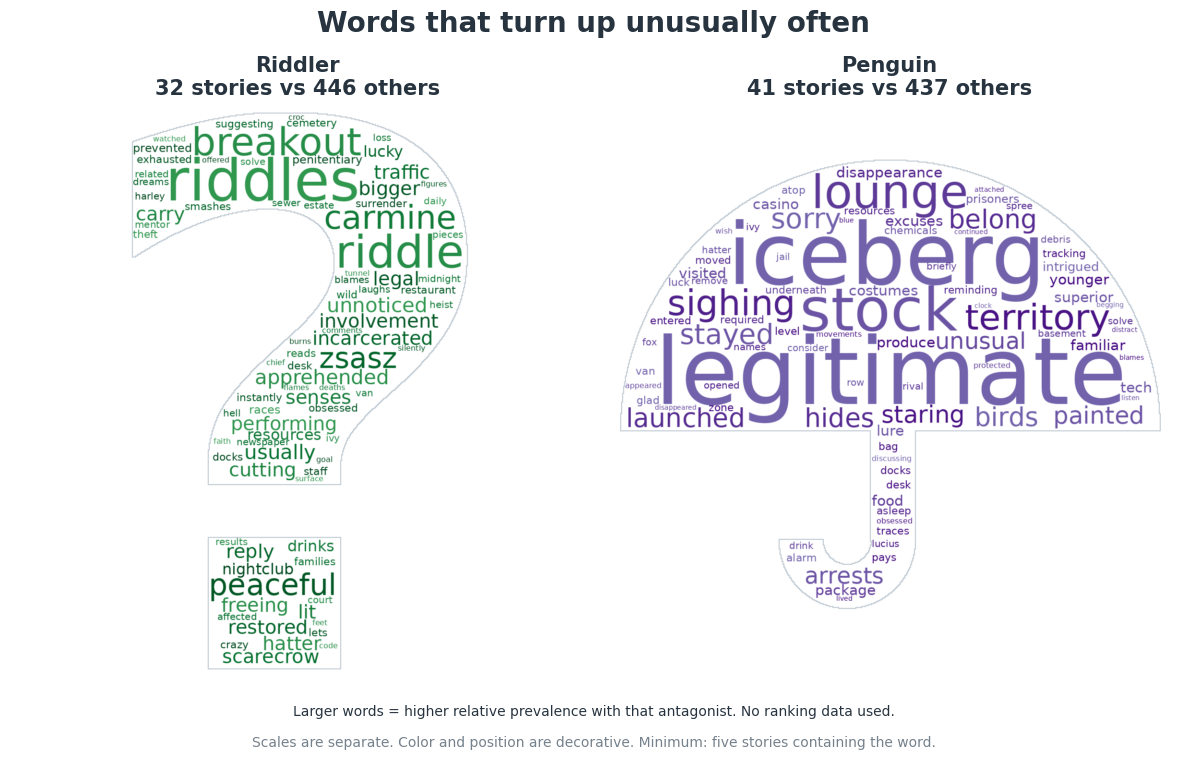

,Antagonist,Word,With this antagonist,Other eligible stories
0,Riddler,riddle,15 / 32,4 / 446
1,Riddler,scarecrow,12 / 32,16 / 446
2,Penguin,legitimate,5 / 41,0 / 437
3,Penguin,iceberg,11 / 41,3 / 437


In [15]:
cloud_stories = s.set_index('story_id').reindex(cloud_docs.story_id)
cast_known = (cloud_stories.cast_scope.eq('selected_narratives')
              & cloud_stories.cast_issue_coverage.eq(1)).to_numpy()
cloud_entities = cloud_stories.antagonists_entity_ids.map(split_set).map(
    lambda values: {re.sub(r' \([^()]+\)$', '', value) for value in values})
cohorts = {
    'Riddler': {'Edward Nashton','Edward Nigma','Edward Nygma','J. Edward Nygma','Riddler'},
    'Penguin': {'Oswald Cobblepot','Penguin'},
}
cloud_tables = []
cloud_members = []
fig,axes = plt.subplots(1,2,figsize=(12,7.8))
for ax,(villain,aliases),palette in zip(axes,cohorts.items(),['Greens','Purples']):
    present = cloud_entities.map(lambda values: bool(values & aliases)).to_numpy() & cast_known
    other = cast_known & ~present
    assert not (present & other).any() and (present | other).sum() == cast_known.sum()
    assert present.sum() >= 5 and other.sum() >= 5
    counts = word_presence[present].sum(axis=0).A1
    other_counts = word_presence[other].sum(axis=0).A1
    score = np.log2(((counts+1)/(present.sum()+2))/((other_counts+1)/(other.sum()+2)))
    table = pd.DataFrame({'villain':villain, 'term':terms,
        'cohort_readings_with_word':counts, 'cohort_readings_total':present.sum(),
        'other_readings_with_word':other_counts, 'other_readings_total':other.sum(),
        'log2_prevalence_ratio':score})
    table = table.loc[(counts >= 5) & (score > 0)].sort_values(
        ['log2_prevalence_ratio','term'], ascending=[False,True]).head(85)
    assert len(table) >= 20 and np.isfinite(table.log2_prevalence_ratio).all()
    cloud_tables.append(table)
    cloud_members.append(pd.DataFrame({'villain':villain,
        'story_id':cloud_docs.loc[cast_known,'story_id'], 'has_antagonist_credit':present[cast_known]}))
    cloud = WordCloud(mask=masks[villain], background_color='white', font_path=font_path,
        random_state=42, max_words=85, scale=2, prefer_horizontal=1,
        colormap=ListedColormap(plt.get_cmap(palette)(np.linspace(.70,.98,8))),
        contour_width=1, contour_color='#BBC6D0').generate_from_frequencies(
            table.set_index('term').log2_prevalence_ratio.to_dict())
    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{villain}\n{present.sum()} stories vs {other.sum()} others', fontsize=15)
cloud_terms = pd.concat(cloud_tables,ignore_index=True)
cloud_terms.to_csv(REPORT/'plot_cloud_villain_words.csv', index=False)
pd.concat(cloud_members,ignore_index=True).to_csv(REPORT/'plot_cloud_villain_cohorts.csv', index=False)
fig.suptitle('Words that turn up unusually often', fontsize=20, fontweight='bold')
fig.text(.5,.075, 'Larger words = higher relative prevalence with that antagonist. No ranking data used.',
    ha='center', fontsize=10)
fig.text(.5,.035, 'Scales are separate. Color and position are decorative. Minimum: five stories containing the word.',
    ha='center', fontsize=10, color=COLORS['grey'])
fig.tight_layout(rect=(0,.10,1,.94))
save_figure(fig, REPORT, 'eda-villain-word-clouds')

examples = cloud_terms[((cloud_terms.villain == 'Riddler') & cloud_terms.term.isin(['riddle','scarecrow']))
    | ((cloud_terms.villain == 'Penguin') & cloud_terms.term.isin(['iceberg','legitimate']))].copy()
examples['With this antagonist'] = examples.cohort_readings_with_word.astype(str) + ' / ' + examples.cohort_readings_total.astype(str)
examples['Other eligible stories'] = examples.other_readings_with_word.astype(str) + ' / ' + examples.other_readings_total.astype(str)
display(examples[['villain','term','With this antagonist','Other eligible stories']].rename(
    columns={'villain':'Antagonist','term':'Word'}).reset_index(drop=True))


“Riddle” appears in **15 of 32** Riddler stories, versus **4 of 446** others. “Scarecrow” appears in **12 of 32**, versus **16 of 446**. The cloud catches his frequent company as well as his gimmick.

Penguin gets “iceberg”: **11 of 41** stories, versus **3 of 437** others. “Legitimate” appears in **5 of 41**, versus **0 of 437**. Crime dressed as respectable business is familiar Penguin territory. But that big word rests on five stories and a zero in the comparison group. Check the examples before treating it as a theme.

Long summaries also have more chances to mention any given word. Riddler's have a median length of **1,422 words**, versus **552** for the other stories. Penguin's have **1,200**, versus **552**. Counting each word once per story limits repetition; it cannot erase that difference in length.

The [word counts](../reports/plot_cloud_common_words.csv), [villain comparisons](../reports/plot_cloud_villain_words.csv), and [story lists](../reports/plot_cloud_villain_cohorts.csv) let you check what sits behind a big word. We're exploring the summaries here, not judging the villains or measuring the comics' prose style.

## What I would read next

I'd start with *Red Rain* and *Unseen*: Moench and Jones at opposite ends of the ranking. Then *Unknowing*, *Madness*, and *Mad*, to compare stories where Hatter really matters. For a contrast in storytelling, try the silence of *Undone* beside the illustrated prose of *The Clown at Midnight*.

For a follow-up, I would record silent pages, words per page, panel density, and the coloring of the edition actually read. That would bring the analysis closer to how the comics tell their stories.

[Predict the rankings](1.0-batchat-rankings.ipynb) · [Compare other audiences](3.0-batchat-versus-the-crowd.ipynb) · [Data dictionary](../references/data_dictionary.md) · [Kaggle setup and sharing](../references/kaggle-sharing.md)